In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Movie Recommendation System
## Milestone 1: Ratings as a Matrix

Team members: Rudra Patel and Kirtan Patel
   
Course: MATH 344L

## Part A: A Small Ratings Matrix

In [49]:
movies = ["Action 1", "Action 2", "Action 3",
          "Romance 1", "Romance 2", "Romance 3"]

users = ["Josh", "Anna", "Simon", "Ethan", "Tobi", "Rose"]

toy = np.array([
    [5, 4, 5, 1, np.nan, 2],
    [4, np.nan, 5, 2, 1, 1],
    [5, 5, np.nan, 1, 2, np.nan],
    [1, 2, 1, 5, 4, np.nan],
    [np.nan, 1, 2, 4, 5, 5],
    [2, 1, np.nan, 5, np.nan, 4]
])

toy_table = pd.DataFrame(toy, index=users, columns=movies)
toy_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Josh,5.0,4.0,5.0,1.0,NaN,2.0
Anna,4.0,NaN,5.0,2.0,1.0,1.0
Simon,5.0,5.0,NaN,1.0,2.0,NaN
Ethan,1.0,2.0,1.0,5.0,4.0,NaN
Tobi,NaN,1.0,2.0,4.0,5.0,5.0
Rose,2.0,1.0,NaN,5.0,NaN,4.0


In [50]:
missing = np.isnan(toy).sum()
print("Missing entries:", missing, "out of", toy.size)

Missing entries: 8 out of 36


The matrix represents ratings from six users for six movies. Each row represents a user and each column represents a movie. The ratings range from 1 to 5, and NaN indicates a missing rating. There are 8 missing ratings out of 36 possible ratings. The goal of the recommendation system is to predict these missing values based on patterns in the existing ratings.

## Part B: The MovieLens Dataset

In [51]:
import os
import urllib.request
import zipfile

if not os.path.exists("ml-100k"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip"
    )
    zipfile.ZipFile("ml-100k.zip").extractall()

In [52]:
ratings = pd.read_csv(
    "ml-100k/u.data",
    sep="\t",
    names=["user", "item", "rating", "time"]
)

ratings.head()

,user,item,rating,time
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


In [53]:
print("Number of ratings:", len(ratings))
print("Number of users:", ratings["user"].nunique())
print("Number of movies:", ratings["item"].nunique())

Number of ratings: 100000
Number of users: 943
Number of movies: 1682


In [54]:
star_counts = ratings["rating"].value_counts().sort_index()
star_counts

average_rating = ratings["rating"].mean()
print("Average rating:", round(average_rating, 3))

Average rating: 3.53


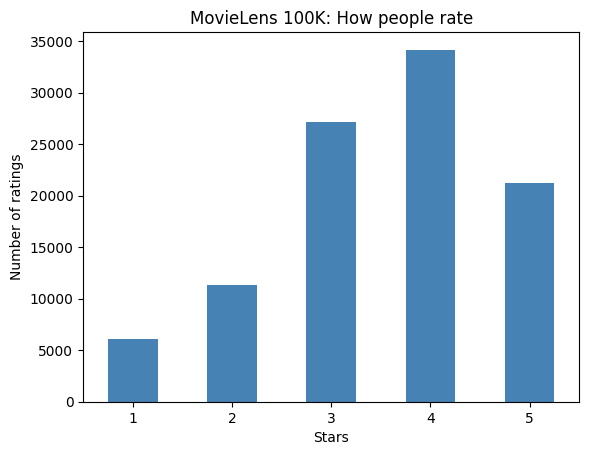

In [55]:
star_counts.plot(kind="bar", color="steelblue", rot=0)

plt.xlabel("Stars")
plt.ylabel("Number of ratings")
plt.title("MovieLens 100K: How people rate")
plt.show()

The MovieLens 100K dataset contains 100,000 ratings from 943 users across 1,682 movies. The average rating is approximately 3.53 stars. The bar chart shows that ratings of 3 and 4 stars are the most common, while 1 star ratings are the least common.

## Part C: Building the User-by-Movie Matrix

In [56]:
R = ratings.pivot_table(
    index="user",
    columns="item",
    values="rating"
)

R.head()

item,1,2,3,4,5,6,7,8,9,10,...,1673,1674,1675,1676,1677,1678,1679,1680,1681,1682
user,,,,,,,,,,,,,,,,,,,,,
1,5.0,3.0,4.0,3.0,3.0,5.0,4.0,1.0,5.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,4.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [57]:
print("Matrix shape:", R.shape)

fraction_missing = R.isna().to_numpy().mean()
print("Fraction missing:", round(fraction_missing, 4))

Matrix shape: (943, 1682)
Fraction missing: 0.937


In [58]:
per_user = ratings.groupby("user").size()

print("Least active user:", per_user.min())
print("Median user:", int(per_user.median()))
print("Most active user:", per_user.max())

Least active user: 20
Median user: 65
Most active user: 737


### Part C: Analysis

The user by movie matrix contains 943 rows and 1,682 columns. Each row represents a user and each column represents a movie. The matrix contains approximately 93.7% missing entries because most users have only rated a small portion of the available movies. The least active user rated 20 movies, the median user rated 65 movies and the most active user rated 737 movies.

We cannot directly apply Singular Value Decomposition (SVD) to this matrix because it contains NaN values. SVD requires a complete numerical matrix so we must first find a way to handle the missing ratings.

## Part D: Which Movies Are Rated Most?

In [59]:
titles = pd.read_csv(
    "ml-100k/u.item",
    sep="|",
    encoding="latin-1",
    header=None,
    usecols=[0, 1],
    names=["item", "title"]
)

titles.head()

,item,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [60]:
stats = ratings.groupby("item")["rating"].agg(["count", "mean"])
stats = stats.join(titles.set_index("item"))

stats.head()

,count,mean,title
item,,,
1,452,3.878319,Toy Story (1995)
2,131,3.206107,GoldenEye (1995)
3,90,3.033333,Four Rooms (1995)
4,209,3.550239,Get Shorty (1995)
5,86,3.302326,Copycat (1995)


In [61]:
top_five = stats.sort_values("count", ascending=False).head(5)
top_five.round(2)

,count,mean,title
item,,,
50,583,4.36,Star Wars (1977)
258,509,3.80,Contact (1997)
100,508,4.16,Fargo (1996)
181,507,4.01,Return of the Jedi (1983)
294,485,3.16,Liar Liar (1997)


### Part D: Analysis

We grouped the movie ratings by movie ID to calculate the total number of ratings and the average rating for each movie. We then connected the movie IDs to their titles and sorted the results by the number of ratings.

Star Wars (1977) received the most ratings, with 583 ratings and an average score of approximately 4.36 stars. This shows that a movie can be popular based on how many people rated it, while its average rating measures how positively viewers rated it.

## Section 7: Exercises


### Exercise 1: Predicting Missing Ratings

In [62]:
for i in range(len(users)):
    for j in range(len(movies)):
        if np.isnan(toy[i, j]):
            print(f"{users[i]} - {movies[j]}")

Josh - Romance 2
Anna - Action 2
Simon - Action 3
Simon - Romance 3
Ethan - Romance 3
Tobi - Action 1
Rose - Action 3
Rose - Romance 2


**Exercise 1: Missing Rating Predictions**

The toy matrix contains eight missing ratings. Based on the ratings of users with similar preferences, I predict:

- Josh — Romance 2: 1
- Anna — Action 2: 4
- Simon — Action 3: 5
- Simon — Romance 3: 1
- Ethan — Romance 3: 5
- Tobi — Action 1: 1
- Rose — Action 3: 1
- Rose — Romance 2: 5

**Justification 1:** Anna would likely rate Action 2 a 4 because Josh and Simon have similar preferences for action movies, and they rated Action 2 highly.

**Justification 2:** Ethan would likely rate Romance 3 a 5 because Tobi and Rose have similar preferences for romance movies and rated Romance 3 highly.

### Exercise 2: Adding a Seventh User

In [63]:
# Add a seventh imaginary user named Alex
new_user = "Alex"

# Alex likes action movies and dislikes romance movies
new_ratings = np.array([5, 4, np.nan, 2, 1, np.nan])

# Add Alex to the existing ratings matrix
toy_extended = np.vstack([toy, new_ratings])
users_extended = users + [new_user]

# Display the updated matrix
toy_extended_table = pd.DataFrame(
    toy_extended,
    index=users_extended,
    columns=movies
)

toy_extended_table

,Action 1,Action 2,Action 3,Romance 1,Romance 2,Romance 3
Josh,5.0,4.0,5.0,1.0,NaN,2.0
Anna,4.0,NaN,5.0,2.0,1.0,1.0
Simon,5.0,5.0,NaN,1.0,2.0,NaN
Ethan,1.0,2.0,1.0,5.0,4.0,NaN
Tobi,NaN,1.0,2.0,4.0,5.0,5.0
Rose,2.0,1.0,NaN,5.0,NaN,4.0
Alex,5.0,4.0,NaN,2.0,1.0,NaN


In [64]:
alex_predictions = {
    "Action 3": 5,
    "Romance 3": 1
}

for movie, rating in alex_predictions.items():
    print(f"Alex - {movie}: Predicted rating = {rating}")

Alex - Action 3: Predicted rating = 5
Alex - Romance 3: Predicted rating = 1


#### Exercise 2: Analysis

I added a seventh imaginary user named Alex, who prefers action movies over romance movies.

Alex rated Action 1 a 5, Action 2 a 4, Romance 1 a 2, and Romance 2 a 1. The ratings for Action 3 and Romance 3 were left missing.

**Predicted Ratings:**
- Action 3: 5
- Romance 3: 1

**Explanation:** I predict Alex would rate Action 3 a 5 because Josh, Anna, and Simon also prefer action movies and gave Action 3 high ratings where available. I predict Alex would rate Romance 3 a 1 because Alex dislikes romance movies, similar to Josh and Anna, who gave Romance 3 low ratings.

### Exercise 3: Missing Entries

In [65]:
# Count the number of missing ratings
missing_count = np.isnan(toy).sum()

# Calculate the fraction of missing entries
fraction_missing_toy = np.isnan(toy).mean()

print("Missing entries:", missing_count)
print("Fraction missing:", round(fraction_missing_toy, 4))
print("Percentage missing:", round(fraction_missing_toy * 100, 2), "%")

Missing entries: 8
Fraction missing: 0.2222
Percentage missing: 22.22 %


#### Exercise 3: Analysis

The command `np.isnan(toy).sum()` counts the total number of missing entries (`NaN` values) in the toy ratings matrix. It returns 8 because there are 8 missing ratings out of 36 possible entries.

To calculate the fraction of missing entries, we can use:

`np.isnan(toy).mean()`

This gives approximately 0.2222, meaning 22.22% of the ratings are missing.

The `np.isnan()` function identifies missing values, and `.mean()` calculates the proportion of entries that are missing.

### Exercise 4: Least Common Star Rating

In [66]:
# Count how many times each star rating appears
star_counts = ratings["rating"].value_counts().sort_index()

# Find the least common rating
least_common_rating = star_counts.idxmin()
least_common_count = star_counts.min()

print("Least common star rating:", least_common_rating)
print("Number of occurrences:", least_common_count)

Least common star rating: 1
Number of occurrences: 6110


#### Exercise 4: Analysis

The least common star rating in the MovieLens 100K dataset is **1 star**, which appears **6,110 times**.

I used `value_counts()` to count how frequently each rating occurs, `idxmin()` to identify the least common rating, and `min()` to find its number of occurrences.

This shows that 1-star ratings are less frequent than ratings of 2, 3, 4, or 5 stars.

### Exercise 5: Average Rating per User

In [67]:
# Calculate the average rating for each user
user_averages = ratings.groupby("user")["rating"].mean()

# Find the user with the highest average rating
highest_user = user_averages.idxmax()
highest_average = user_averages.max()

print("User with highest average rating:", highest_user)
print("Highest average rating:", round(highest_average, 3))

User with highest average rating: 849
Highest average rating: 4.87


In [68]:
# Count how many movies the highest-rated user reviewed
user_rating_count = ratings.groupby("user").size()

print("User ID:", highest_user)
print("Average rating:", round(highest_average, 3))
print("Number of movies rated:", user_rating_count[highest_user])

User ID: 849
Average rating: 4.87
Number of movies rated: 23


#### Exercise 5: Analysis

Using `groupby()`, I calculated the average movie rating for each user in the MovieLens 100K dataset.

User 849 has the highest average rating, approximately 4.87 stars.

However, we should be cautious about calling this person the "most positive" user because they only rated 31 movies. A user who rates fewer movies may have a higher average simply because they choose movies they already expect to enjoy.

Also, different users may use the rating scale differently, so having the highest average does not necessarily mean someone is the most positive overall.

### Exercise 6: Ratings vs. Matrix R

The `ratings` table shows the original movie ratings, where each row is one rating from a user for a movie. It includes the user ID, movie ID, rating, and time.

The matrix `R` is different because each row represents a user and each column represents a movie. It shows the ratings in a matrix, and if someone hasn't rated a movie, it shows `NaN`.

Basically, `ratings` stores each rating separately, while `R` organizes everything into a matrix so we can use linear algebra to make movie recommendations.

### Exercise 7: Singular Value Decomposition (SVD)

If the rating matrix had no missing entries, we could use SVD because every value would be a number instead of `NaN`. SVD needs a complete matrix to work properly.

But this still wouldn't completely solve the recommendation problem because having all the ratings doesn't automatically tell us which movies a user would enjoy in the future. We would still need to use SVD to find patterns in the ratings and make useful recommendations.

### Exercise 8: Hidden Factors Affecting Movie Ratings

Three hidden factors that could affect movie ratings are action, comedy, and romance.

**1. Action:** If a user has a high value for action, it means they really enjoy action movies. If a movie has a high action value, it means the movie has a lot of action scenes.

**2. Comedy:** If a user has a high value for comedy, it means they prefer funny movies. If a movie has a high comedy value, it means the movie has a lot of humor.

**3. Romance:** If a user has a high value for romance, it means they enjoy romantic movies. If a movie has a high romance value, it means romance is a major part of the movie.